# EDA：Predicting Airline Satisfaction

目的：特徴量の分布と `satisfaction` との関係、train / test の分布差、評価項目の 0（該当なし）の扱いを確認する。

## まとめ（2026-10-22）

- **train / test の分布はほぼ同じ**：カテゴリ比率・数値の平均とも差は小さい。CV と LB は連動しやすいと見込める
- **評価項目の 0 は順序値として扱えない**：inflight_wifi_service は 0 の満足率 0.887（1〜3 は 0.27〜0.39）、online_boarding も 0 で 0.620。0 を「該当なし」とみなすフラグや、カテゴリとして扱う特徴量が候補
- **強く効きそうな列**：class（Business 0.73 / Eco 0.17）、	ype_of_travel（Business 0.58 / Personal 0.10）、online_boarding、inflight_wifi_service、inflight_entertainment
- **遅延**：出発・到着遅延の相関 0.84、両方 0 が 87%。平均は約 1 分と、元データ（約 15 分）より大幅に小さい。合成データは元データと分布が違う点に注意（元データ追加時の検証ポイント）
- rrival_delay_in_minutes の欠損はごく少ない（train 292 / test 130）
- 重複行・train と test の完全一致行はなし


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent))
from src.common import CAT_COLS, NUM_COLS, RATING_COLS, TARGET, load_data

pd.set_option('display.width', 200)
train, test = load_data()
print(train.shape, test.shape)

(699635, 23) (299844, 22)


## 1. ターゲットと欠損

In [2]:
print(train[TARGET].value_counts(normalize=True).round(4))
pd.DataFrame({'train': train.isna().sum(), 'test': test.isna().sum()}).query('train > 0 or test > 0')

satisfaction
0    0.5564
1    0.4436
Name: proportion, dtype: float64


,train,test
arrival_delay_in_minutes,292,130.0


## 2. カテゴリ列：件数と満足率

In [3]:
for col in CAT_COLS:
    s = train.groupby(col, observed=True)[TARGET].agg(['size', 'mean'])
    s['test_share'] = test[col].value_counts(normalize=True)
    s['train_share'] = s['size'] / len(train)
    print(s.round(4), '\n')

          size    mean  test_share  train_share
gender                                         
Female  347952  0.4380      0.4989       0.4973
Male    351683  0.4491      0.5011       0.5027 

                     size    mean  test_share  train_share
customer_type                                             
Loyal Customer     576990  0.4951      0.8261       0.8247
disloyal Customer  122645  0.2009      0.1739       0.1753 

                   size    mean  test_share  train_share
type_of_travel                                          
Business travel  497441  0.5843      0.7108        0.711
Personal Travel  202194  0.0973      0.2892        0.289 

            size    mean  test_share  train_share
class                                            
Business  342212  0.7253      0.4890       0.4891
Eco       327404  0.1676      0.4676       0.4680
Eco Plus   30019  0.2422      0.0433       0.0429 



## 3. 評価項目（0〜5）：値ごとの満足率

0 が「該当なし」なら、満足率が 1〜5 の並びから外れるはず。

In [4]:
rate = pd.DataFrame({c: train.groupby(c)[TARGET].mean() for c in RATING_COLS}).T
share0 = pd.Series({c: (train[c] == 0).mean() for c in RATING_COLS}, name='0の割合')
rate.round(3).join(share0.round(4))

,0,1,2,3,4,5,0の割合
inflight_wifi_service,0.887,0.391,0.270,0.276,0.622,0.950,0.0187
departure_arrival_time_convenient,0.478,0.506,0.453,0.449,0.402,0.437,0.0368
ease_of_online_booking,0.708,0.415,0.314,0.320,0.556,0.754,0.0230
gate_location,0.543,0.514,0.465,0.337,0.411,0.625,0.0021
food_and_drink,0.219,0.171,0.394,0.407,0.525,0.565,0.0014
online_boarding,0.620,0.105,0.085,0.128,0.642,0.875,0.0131
seat_comfort,0.184,0.174,0.172,0.185,0.571,0.671,0.0012
inflight_entertainment,0.140,0.127,0.173,0.239,0.620,0.671,0.0015
on_board_service,0.147,0.174,0.220,0.291,0.541,0.657,0.0011
leg_room_service,0.270,0.189,0.248,0.266,0.594,0.615,0.0024


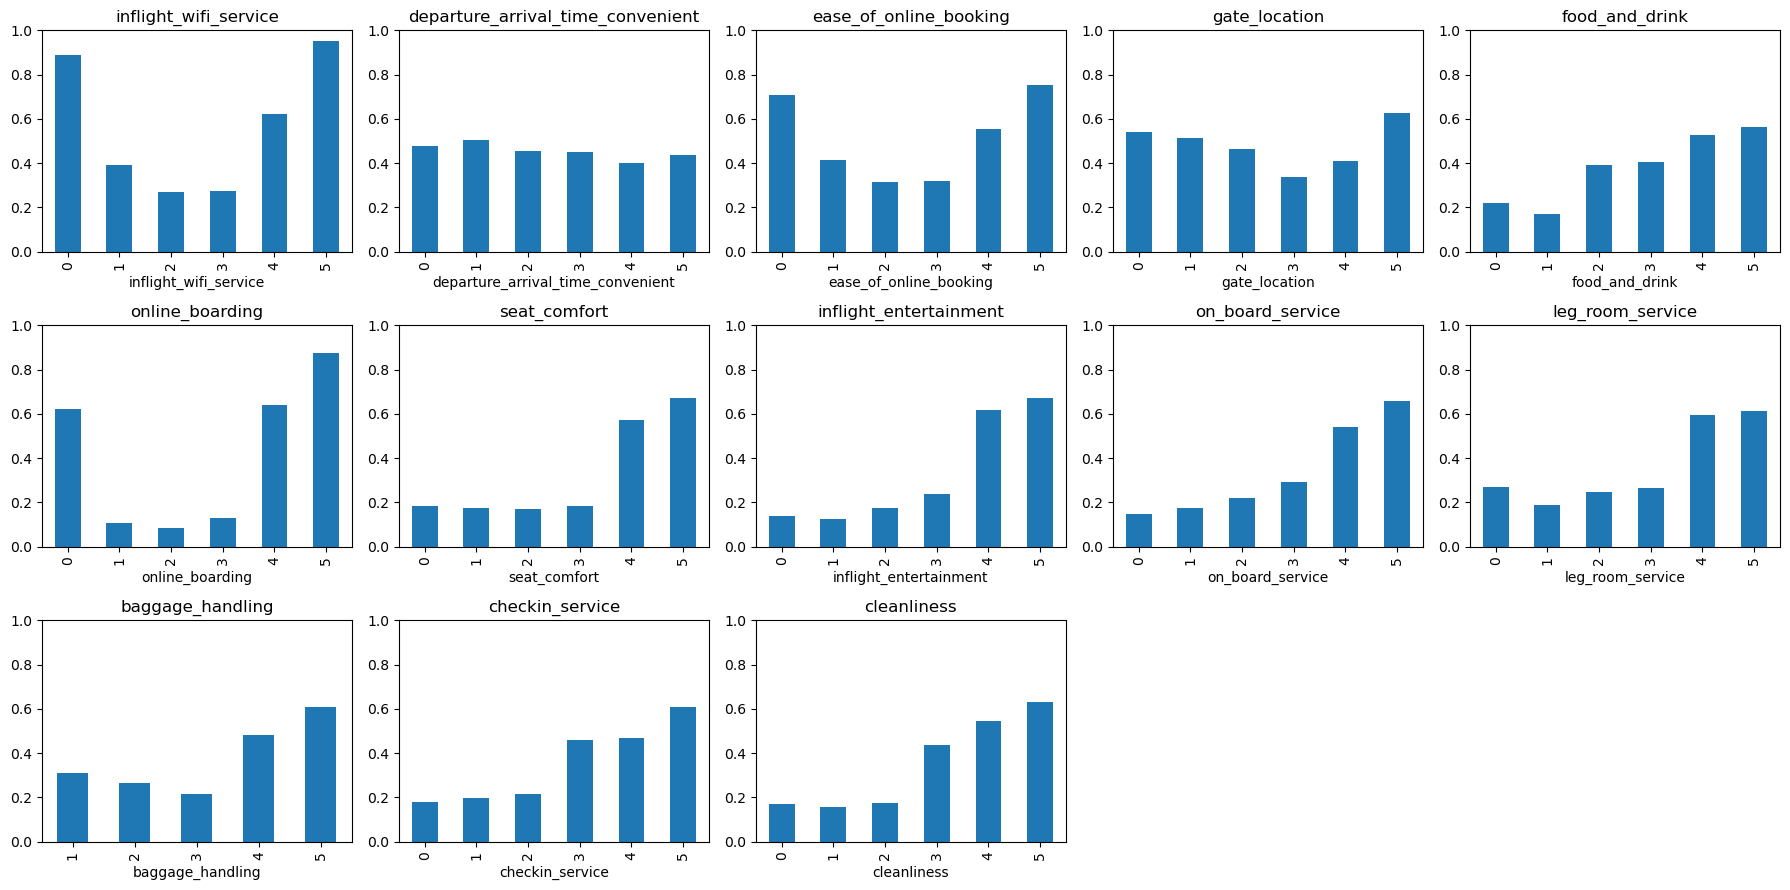

In [5]:
fig, axes = plt.subplots(3, 5, figsize=(18, 9))
for ax, c in zip(axes.flat, RATING_COLS):
    train.groupby(c)[TARGET].mean().plot.bar(ax=ax, title=c, ylim=(0, 1))
for ax in axes.flat[len(RATING_COLS):]:
    ax.axis('off')
plt.tight_layout()

## 4. 数値列：train / test の分布と満足率

In [6]:
pd.DataFrame({'train': train[NUM_COLS].describe().T['mean'], 'test': test[NUM_COLS].describe().T['mean']}).round(2)

,train,test
age,39.00,38.99
flight_distance,1353.78,1353.37
departure_delay_in_minutes,1.18,1.16
arrival_delay_in_minutes,1.13,1.12


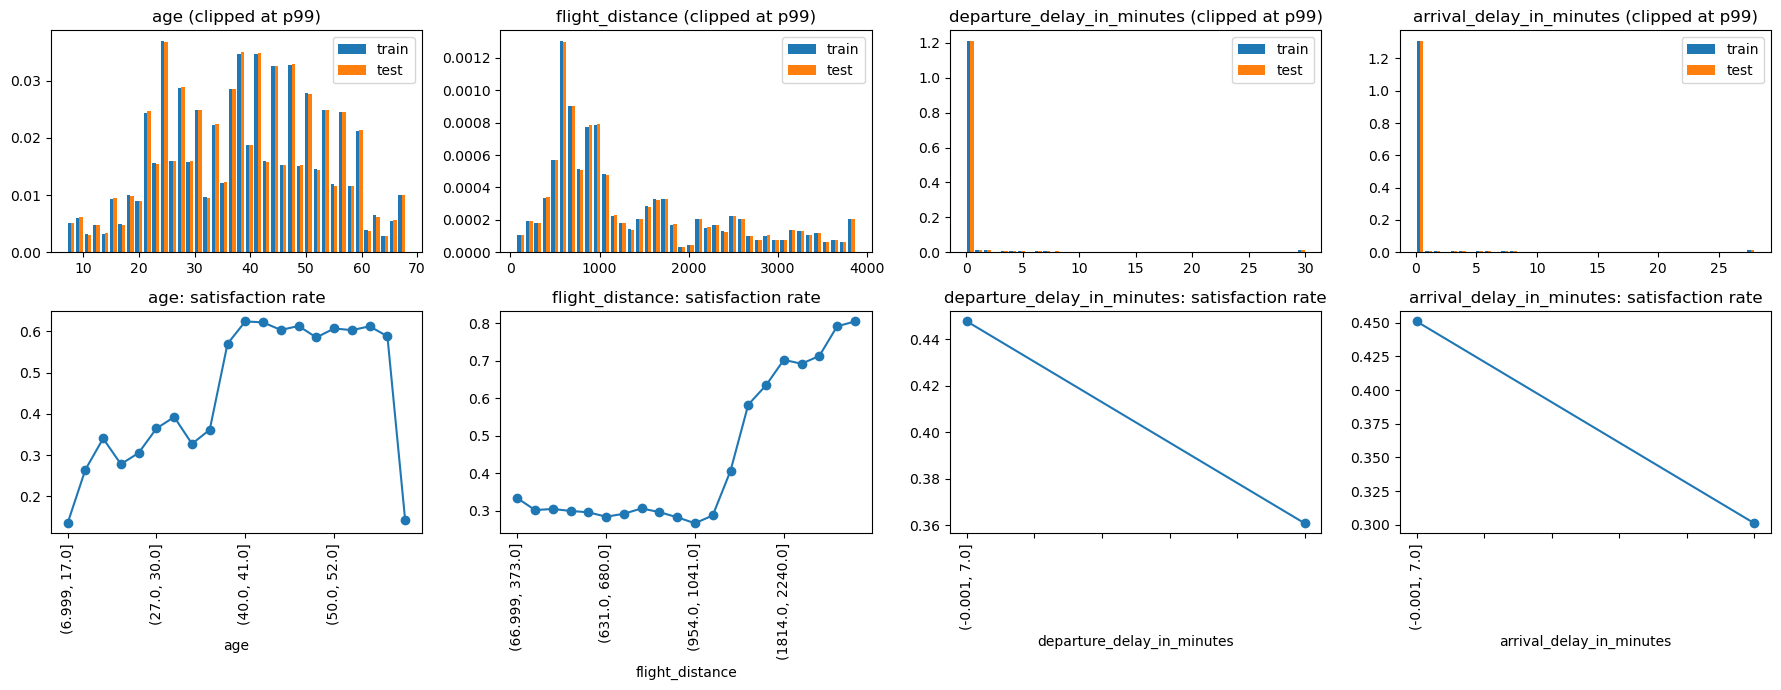

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, c in enumerate(NUM_COLS):
    clip = train[c].quantile(0.99)
    axes[0, i].hist([train[c].clip(upper=clip).dropna(), test[c].clip(upper=clip).dropna()], bins=40, density=True, label=['train', 'test'])
    axes[0, i].set_title(f'{c} (clipped at p99)'); axes[0, i].legend()
    b = pd.qcut(train[c], 20, duplicates='drop')
    train.groupby(b, observed=True)[TARGET].mean().plot(ax=axes[1, i], marker='o', title=f'{c}: satisfaction rate', rot=90)
plt.tight_layout()

## 5. 遅延：出発遅延と到着遅延の関係

In [8]:
d = train[['departure_delay_in_minutes', 'arrival_delay_in_minutes']].dropna()
print('相関:', d.corr().iloc[0, 1].round(4))
print('両方 0 の割合:', ((d == 0).all(axis=1)).mean().round(4))

相関: 0.842
両方 0 の割合: 0.8669


## 6. 重複行

合成データでは、元データと同じ行や train / test 間の重複がヒントになることがある。

In [9]:
feat = [c for c in train.columns if c not in ('id', TARGET)]
print('train 内の重複（特徴量のみ）:', train.duplicated(subset=feat).sum())
merged = test[feat].merge(train[feat].drop_duplicates(), how='inner')
print('train と完全一致する test 行:', len(merged))

train 内の重複（特徴量のみ）: 0
train と完全一致する test 行: 0
